In [1]:
!pip install shap



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

customers = pd.read_csv("C:/Users/lenovo/Desktop/FinRisk-X/data/raw/customers.csv")

static_profile = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/customer_financial_profile.csv"
)

risk_fusion = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/final_risk_scores.csv"
)

credit_model = joblib.load(
    "C:/Users/lenovo/Desktop/FinRisk-X/models/credit_risk_xgb.pkl"
)

credit_features = joblib.load(
    "C:/Users/lenovo/Desktop/FinRisk-X/models/credit_risk_features.pkl"
)

print("Files loaded successfully.")
print("Customers:", len(customers))
print("Risk records:", len(risk_fusion))

Files loaded successfully.
Customers: 10000
Risk records: 10000


In [4]:
X_credit = static_profile[credit_features].copy()

X_credit = (
    X_credit
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print("Credit feature shape:", X_credit.shape)

Credit feature shape: (10000, 25)


In [5]:
explainer = shap.TreeExplainer(credit_model)

shap_values = explainer.shap_values(X_credit)

print("SHAP values shape:", np.array(shap_values).shape)

SHAP values shape: (10000, 25)


In [6]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

global_importance = pd.DataFrame({
    "feature": credit_features,
    "mean_abs_shap": mean_abs_shap
}).sort_values(
    "mean_abs_shap",
    ascending=False
)

global_importance.head(15)

,feature,mean_abs_shap
22,debt_to_income,0.313848
4,savings,0.312813
2,employment_years,0.305991
5,existing_debt,0.168506
6,credit_score,0.148107
1,annual_income,0.110680
24,savings_to_loan,0.101223
21,loan_to_income,0.070600
19,spending_volatility,0.069657
11,total_monthly_payment,0.062177


In [7]:
global_importance.to_csv(
    "../data/processed/credit_shap_global_importance.csv",
    index=False
)

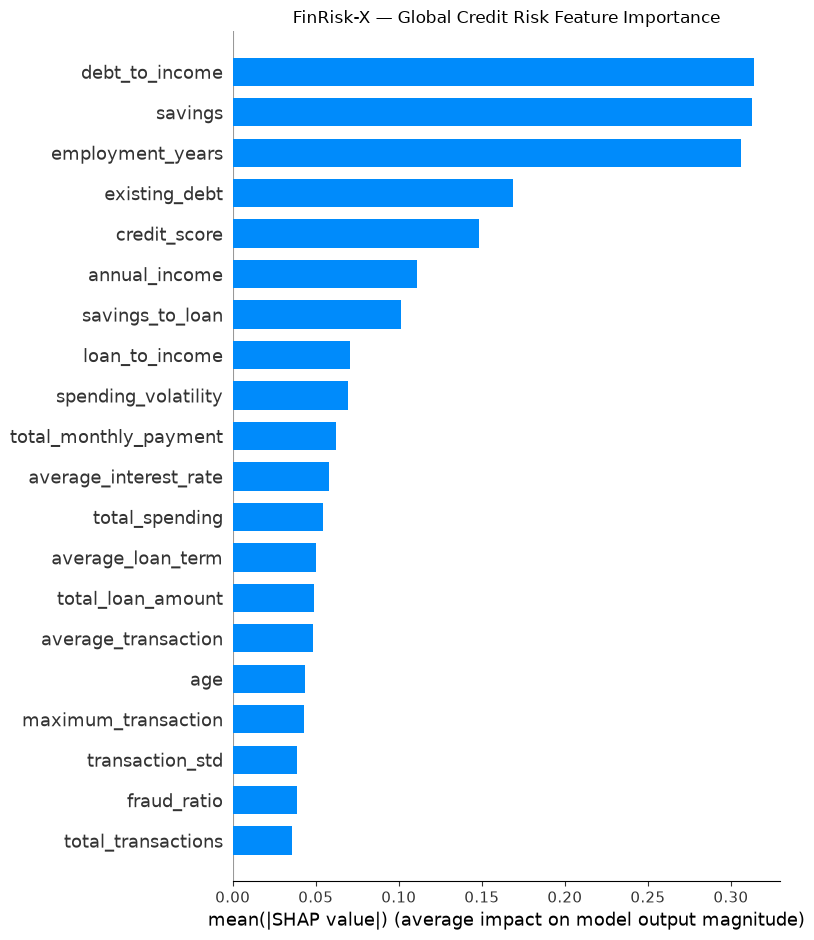

In [8]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_credit,
    plot_type="bar",
    show=False
)

plt.title(
    "FinRisk-X — Global Credit Risk Feature Importance"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/credit_shap_global_importance.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

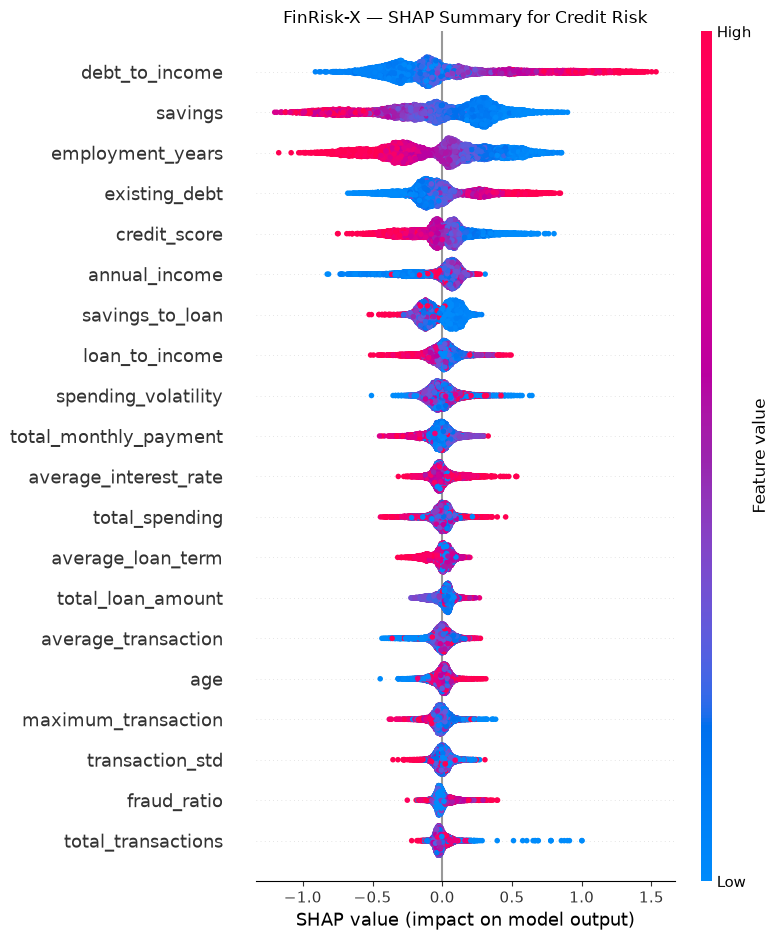

In [9]:
plt.figure(figsize=(11, 8))

shap.summary_plot(
    shap_values,
    X_credit,
    show=False
)

plt.title(
    "FinRisk-X — SHAP Summary for Credit Risk"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/credit_shap_summary.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [10]:
customer_id = risk_fusion.iloc[0]["customer_id"]

customer_id

np.int64(100001)

In [11]:
customer_index = static_profile.index[
    static_profile["customer_id"] == customer_id
][0]

customer_row = X_credit.loc[[customer_index]]

customer_shap_values = shap_values[customer_index]

print("Customer ID:", customer_id)
print("Customer row shape:", customer_row.shape)

Customer ID: 100001
Customer row shape: (1, 25)


In [12]:
individual_explanation = pd.DataFrame({
    "feature": credit_features,
    "feature_value": customer_row.iloc[0].values,
    "shap_value": customer_shap_values
})

individual_explanation["absolute_shap"] = (
    individual_explanation["shap_value"].abs()
)

individual_explanation = individual_explanation.sort_values(
    "absolute_shap",
    ascending=False
)

individual_explanation.head(10)

,feature,feature_value,shap_value,absolute_shap
2,employment_years,0.000000,0.515043,0.515043
24,savings_to_loan,0.048933,-0.123518,0.123518
13,total_spending,69646.230000,-0.121391,0.121391
19,spending_volatility,0.247293,-0.116712,0.116712
21,loan_to_income,0.442421,0.098434,0.098434
5,existing_debt,185332.880592,-0.090848,0.090848
22,debt_to_income,0.043929,-0.088322,0.088322
14,average_transaction,3165.737727,0.068170,0.068170
8,total_loan_amount,289475.000000,0.062657,0.062657
0,age,59.000000,0.059040,0.059040


In [13]:
individual_explanation.to_csv(
    "../data/processed/individual_customer_shap_explanation.csv",
    index=False
)

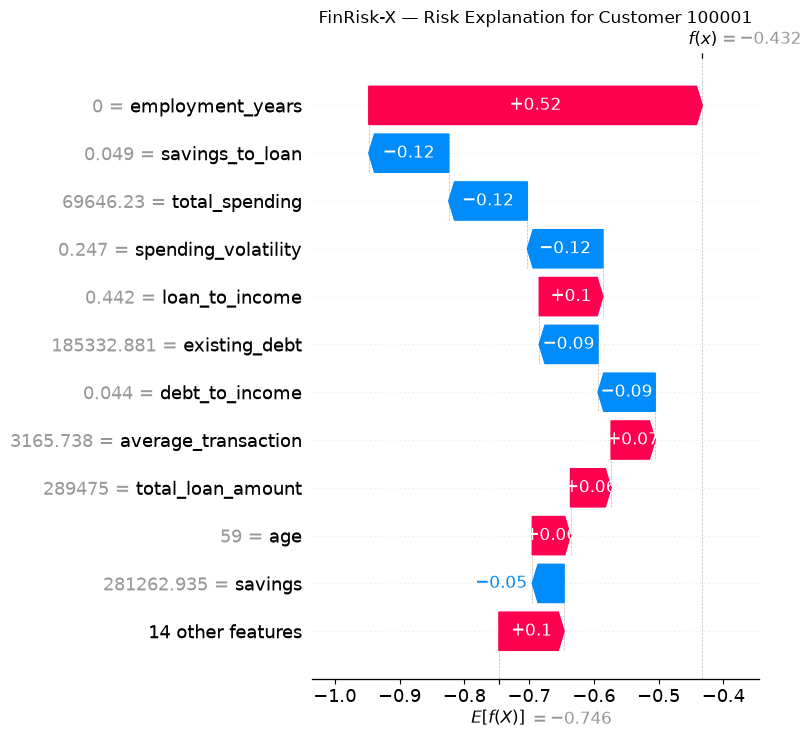

In [14]:
customer_explanation = shap.Explanation(
    values=customer_shap_values,
    base_values=explainer.expected_value,
    data=customer_row.iloc[0].values,
    feature_names=credit_features
)

shap.plots.waterfall(
    customer_explanation,
    max_display=12,
    show=False
)

plt.title(
    f"FinRisk-X — Risk Explanation for Customer {customer_id}"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/individual_customer_shap_waterfall.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [16]:
top_reasons = individual_explanation.head(5).copy()

risk_reasons = []

for _, row in top_reasons.iterrows():
    direction = (
        "increased"
        if row["shap_value"] > 0
        else "reduced"
    )

    reason = (
        f"{row['feature']} {direction} the predicted credit risk"
    )

    risk_reasons.append(reason)

risk_reasons

['employment_years increased the predicted credit risk',
 'savings_to_loan reduced the predicted credit risk',
 'total_spending reduced the predicted credit risk',
 'spending_volatility reduced the predicted credit risk',
 'loan_to_income increased the predicted credit risk']

In [17]:
for index, reason in enumerate(risk_reasons, start=1):
    print(f"{index}. {reason}")

1. employment_years increased the predicted credit risk
2. savings_to_loan reduced the predicted credit risk
3. total_spending reduced the predicted credit risk
4. spending_volatility reduced the predicted credit risk
5. loan_to_income increased the predicted credit risk


In [18]:
explanation_records = []

for index, row in static_profile.iterrows():

    customer_shap = shap_values[index]

    explanation_df = pd.DataFrame({
        "feature": credit_features,
        "shap_value": customer_shap
    })

    explanation_df["absolute_shap"] = (
        explanation_df["shap_value"].abs()
    )

    top_features = explanation_df.sort_values(
        "absolute_shap",
        ascending=False
    ).head(3)

    reasons = []

    for _, feature_row in top_features.iterrows():

        direction = (
            "increased"
            if feature_row["shap_value"] > 0
            else "reduced"
        )

        reasons.append(
            f"{feature_row['feature']} {direction} risk"
        )

    explanation_records.append({
        "customer_id": row["customer_id"],
        "reason_1": reasons[0],
        "reason_2": reasons[1],
        "reason_3": reasons[2]
    })

customer_explanations = pd.DataFrame(
    explanation_records
)

customer_explanations.head()

,customer_id,reason_1,reason_2,reason_3
0,100001,employment_years increased risk,savings_to_loan reduced risk,total_spending reduced risk
1,100002,employment_years increased risk,savings increased risk,payment_to_income increased risk
2,100003,credit_score increased risk,debt_to_income reduced risk,savings reduced risk
3,100004,debt_to_income reduced risk,total_spending increased risk,annual_income increased risk
4,100005,debt_to_income increased risk,existing_debt increased risk,savings reduced risk


In [19]:
customer_explanations.to_csv(
    "../data/processed/customer_risk_explanations.csv",
    index=False
)

In [20]:
final_risk_explanations = risk_fusion.merge(
    customer_explanations,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

final_risk_explanations.head()

,customer_id,credit_risk_probability,credit_risk_score,temporal_risk_probability,temporal_risk_score,avg_fraud_probability,max_fraud_probability,avg_anomaly_score,max_anomaly_score,avg_hybrid_fraud_score,max_hybrid_fraud_score,fraud_risk_score,graph_risk_score,financial_health_score,financial_health_risk_score,finrisk_score,risk_category,reason_1,reason_2,reason_3
0,100001,0.393545,39.354540,0.351935,35.193510,0.262764,0.783083,0.185125,0.816251,0.239472,0.693558,51.192378,20.645161,64.975851,35.024149,38.242348,Moderate,employment_years increased risk,savings_to_loan reduced risk,total_spending reduced risk
1,100002,0.665469,66.546906,0.315314,31.531355,0.313527,0.803767,0.221139,0.709282,0.285810,0.620303,48.650618,29.582111,65.109057,34.890943,46.359409,Moderate,employment_years increased risk,savings increased risk,payment_to_income increased risk
2,100003,0.515152,51.515220,0.410704,41.070427,0.476873,0.783061,0.261322,0.502814,0.412207,0.614310,53.346915,27.661290,55.265966,44.734034,45.627977,Moderate,credit_score increased risk,debt_to_income reduced risk,savings reduced risk
3,100004,0.411317,41.131725,0.357690,35.768967,0.266366,0.797005,0.227899,0.488348,0.254826,0.633866,48.225006,41.500701,70.999953,29.000047,40.674674,Moderate,debt_to_income reduced risk,total_spending increased risk,annual_income increased risk
4,100005,0.573910,57.391030,0.325702,32.570225,0.295973,0.812917,0.247687,0.494577,0.281487,0.702518,53.410559,12.903226,56.226856,43.773144,43.396794,Moderate,debt_to_income increased risk,existing_debt increased risk,savings reduced risk


In [21]:
final_risk_explanations.to_csv(
    "../data/processed/final_risk_scores_explainable.csv",
    index=False
)

In [22]:
print("=" * 60)
print("FinRisk-X — Phase 11 Validation")
print("=" * 60)

print("\nCustomers:", len(final_risk_explanations))
print(
    "Unique customers:",
    final_risk_explanations["customer_id"].nunique()
)

print("\nExplanation columns:")
print([
    "reason_1",
    "reason_2",
    "reason_3"
])

print("\nMissing explanations:")
print(
    final_risk_explanations[
        ["reason_1", "reason_2", "reason_3"]
    ].isna().sum()
)

print("\nGlobal SHAP importance:")
print(global_importance.head(10))

print("\n" + "=" * 60)
print("PHASE 11 COMPLETE")
print("=" * 60)

FinRisk-X — Phase 11 Validation

Customers: 10000
Unique customers: 10000

Explanation columns:
['reason_1', 'reason_2', 'reason_3']

Missing explanations:
reason_1    0
reason_2    0
reason_3    0
dtype: int64

Global SHAP importance:
                  feature  mean_abs_shap
22         debt_to_income       0.313848
4                 savings       0.312813
2        employment_years       0.305991
5           existing_debt       0.168506
6            credit_score       0.148107
1           annual_income       0.110680
24        savings_to_loan       0.101223
21         loan_to_income       0.070600
19    spending_volatility       0.069657
11  total_monthly_payment       0.062177

PHASE 11 COMPLETE
